# 03 Deep ML Modeling

Goal: build a stronger late-delivery model before interpretation/economic analysis.

This notebook does:
1. Leakage-safe feature building.
2. Temporal train/validation/test split.
3. Multi-model training.
4. Threshold tuning using business cost: `FP*15 + FN*155`.
5. Final test evaluation with best model + threshold.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

sns.set_theme(style="whitegrid")

DATA_PATH = Path("../datasets/processed/olist_merged_clean.csv")
df = pd.read_csv(DATA_PATH)

for c in [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]:
    if c in df.columns:
        df[c] = pd.to_datetime(df[c], errors="coerce")

print("Loaded shape:", df.shape)
print("Late rate (%):", round(df["is_late"].mean() * 100, 2))

Loaded shape: (96189, 34)
Late rate (%): 7.94


In [2]:
def build_features_leakage_safe(frame: pd.DataFrame) -> pd.DataFrame:
    feat = frame.copy()

    # Time features
    feat["month"] = feat["order_purchase_timestamp"].dt.month
    feat["hour_of_day"] = feat["order_purchase_timestamp"].dt.hour
    feat["is_peak_season"] = feat["month"].isin([4, 5, 6]).astype(int)
    feat["same_city"] = (
        feat["customer_city"].astype(str).str.lower()
        == feat["seller_city"].astype(str).str.lower()
    ).astype(int)

    # Numeric interactions
    feat["product_category"] = feat["primary_category"].fillna("unknown")
    feat["seller_key"] = (
        feat["seller_zip_code_prefix"].astype(str)
        + "_"
        + feat["seller_city"].astype(str)
        + "_"
        + feat["seller_state"].astype(str)
    )
    feat["seller_order_count"] = feat.groupby("seller_key")["order_id"].transform("count")
    feat["seller_state_volume"] = feat.groupby("seller_state")["order_id"].transform("count")
    feat["distance_x_weight"] = feat["distance_km"] * feat["max_weight_g"]
    feat["freight_x_distance"] = feat["total_freight"] / feat["distance_km"].clip(lower=1)

    # Temporal split masks
    train_mask = feat["order_purchase_timestamp"] < pd.Timestamp("2018-01-01")
    val_mask = (feat["order_purchase_timestamp"] >= pd.Timestamp("2018-01-01")) & (
        feat["order_purchase_timestamp"] < pd.Timestamp("2018-07-01")
    )
    test_mask = (feat["order_purchase_timestamp"] >= pd.Timestamp("2018-07-01")) & (
        feat["order_purchase_timestamp"] < pd.Timestamp("2018-09-01")
    )

    # Train-only target encoding
    global_rate = feat.loc[train_mask, "is_late"].mean()

    def te(col):
        mapping = feat.loc[train_mask].groupby(col)["is_late"].mean()
        return feat[col].map(mapping).fillna(global_rate)

    feat["seller_state_te"] = te("seller_state")
    feat["category_late_rate"] = te("product_category")
    feat["route_key"] = feat["seller_state"].astype(str) + "->" + feat["customer_state"].astype(str)
    feat["route_late_rate"] = te("route_key")
    feat["seller_late_rate"] = te("seller_key")

    return feat, train_mask, val_mask, test_mask


feat, train_mask, val_mask, test_mask = build_features_leakage_safe(df)
print("Train/Val/Test:", train_mask.sum(), val_mask.sum(), test_mask.sum())

Train/Val/Test: 43412 40270 12507


In [3]:
feature_cols = [
    "distance_km",
    "total_price",
    "total_freight",
    "max_weight_g",
    "n_items",
    "payment_installments",
    "same_state",
    "estimated_delivery_days",
    "product_photos_qty",
    "hour_of_day",
    "is_peak_season",
    "same_city",
    "seller_order_count",
    "seller_state_volume",
    "distance_x_weight",
    "freight_x_distance",
    "seller_state_te",
    "category_late_rate",
    "route_late_rate",
    "seller_late_rate",
    "payment_type",
    "customer_state",
    "seller_state",
    "product_category",
]
feature_cols = [c for c in feature_cols if c in feat.columns]

X_train = feat.loc[train_mask, feature_cols].copy()
y_train = feat.loc[train_mask, "is_late"].astype(int)
X_val = feat.loc[val_mask, feature_cols].copy()
y_val = feat.loc[val_mask, "is_late"].astype(int)
X_test = feat.loc[test_mask, feature_cols].copy()
y_test = feat.loc[test_mask, "is_late"].astype(int)

num_cols = [c for c in feature_cols if pd.api.types.is_numeric_dtype(feat[c])]
cat_cols = [c for c in feature_cols if c not in num_cols]

pre = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline(
                steps=[
                    ("imp", SimpleImputer(strategy="median")),
                    ("sc", StandardScaler()),
                ]
            ),
            num_cols,
        ),
        (
            "cat",
            Pipeline(
                steps=[
                    ("imp", SimpleImputer(strategy="most_frequent")),
                    ("ohe", OneHotEncoder(handle_unknown="ignore")),
                ]
            ),
            cat_cols,
        ),
    ]
)

print("Using features:", len(feature_cols))
print("Numeric:", len(num_cols), "Categorical:", len(cat_cols))
print("Shapes ->", X_train.shape, X_val.shape, X_test.shape)

Using features: 24
Numeric: 20 Categorical: 4
Shapes -> (43412, 24) (40270, 24) (12507, 24)


In [4]:
def eval_with_threshold_sweep(y_true, y_prob, model_name):
    thresholds = np.arange(0.05, 0.96, 0.01)
    best = None

    for t in thresholds:
        y_pred = (y_prob >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
        cost = fp * 15 + fn * 155
        row = {
            "model": model_name,
            "threshold": float(t),
            "cost": int(cost),
            "recall": float(recall_score(y_true, y_pred, zero_division=0)),
            "precision": float(precision_score(y_true, y_pred, zero_division=0)),
            "f1": float(f1_score(y_true, y_pred, zero_division=0)),
            "fp": int(fp),
            "fn": int(fn),
            "tp": int(tp),
            "tn": int(tn),
        }
        if best is None or row["cost"] < best["cost"]:
            best = row

    best["auc"] = float(roc_auc_score(y_true, y_prob))
    best["pr_auc"] = float(average_precision_score(y_true, y_prob))
    return best


models = {
    "LogisticBalanced": LogisticRegression(max_iter=2500, class_weight="balanced", C=0.8),
    "RandomForest": RandomForestClassifier(
        n_estimators=600,
        max_depth=None,
        min_samples_leaf=5,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1,
    ),
    "ExtraTrees": ExtraTreesClassifier(
        n_estimators=700,
        max_depth=None,
        min_samples_leaf=3,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1,
    ),
}

val_rows = []
trained = {}

for name, clf in models.items():
    pipe = Pipeline(steps=[("pre", pre), ("clf", clf)])
    pipe.fit(X_train, y_train)
    val_prob = pipe.predict_proba(X_val)[:, 1]
    best = eval_with_threshold_sweep(y_val, val_prob, name)
    val_rows.append(best)
    trained[name] = pipe

val_results = pd.DataFrame(val_rows).sort_values("cost").reset_index(drop=True)
val_results

,model,threshold,cost,recall,precision,f1,fp,fn,tp,tn,auc,pr_auc
0,LogisticBalanced,0.41,406765,0.665993,0.163798,0.262930,13457,1322,2636,22855,0.694711,0.184780
1,RandomForest,0.26,449735,0.576049,0.152784,0.241513,12643,1678,2280,23669,0.661110,0.216036
2,ExtraTrees,0.33,456775,0.582617,0.147001,0.234767,13381,1652,2306,22931,0.652656,0.198738


In [5]:
best_model_name = val_results.iloc[0]["model"]
best_threshold = float(val_results.iloc[0]["threshold"])

best_pipe = trained[best_model_name]
test_prob = best_pipe.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= best_threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, test_pred).ravel()

test_summary = pd.DataFrame(
    [
        {
            "best_model": best_model_name,
            "threshold_from_val": best_threshold,
            "AUC": roc_auc_score(y_test, test_prob),
            "PR_AUC": average_precision_score(y_test, test_prob),
            "Recall": recall_score(y_test, test_pred, zero_division=0),
            "Precision": precision_score(y_test, test_pred, zero_division=0),
            "F1": f1_score(y_test, test_pred, zero_division=0),
            "Cost_FP15_FN155": int(fp * 15 + fn * 155),
            "FP": int(fp),
            "FN": int(fn),
            "TP": int(tp),
            "TN": int(tn),
            "Flagged_%": round(100 * test_pred.mean(), 2),
        }
    ]
)

print("Best model on validation:", best_model_name)
print("Best threshold:", round(best_threshold, 3))
test_summary

Best model on validation: LogisticBalanced
Best threshold: 0.41


,best_model,threshold_from_val,AUC,PR_AUC,Recall,Precision,F1,Cost_FP15_FN155,FP,FN,TP,TN,Flagged_%
0,LogisticBalanced,0.41,0.604358,0.093579,0.778661,0.086268,0.155327,139215,7266,195,686,4360,63.58


In [7]:
# Optional production-style step:
# after model/threshold selection on validation,
# refit the chosen model on Train+Validation and evaluate on Test.

trainval_mask = train_mask | val_mask
X_trainval = feat.loc[trainval_mask, feature_cols].copy()
y_trainval = feat.loc[trainval_mask, "is_late"].astype(int)

best_clf = models[best_model_name]
best_pipe_refit = Pipeline(steps=[("pre", pre), ("clf", best_clf)])
best_pipe_refit.fit(X_trainval, y_trainval)

test_prob_refit = best_pipe_refit.predict_proba(X_test)[:, 1]
test_pred_refit = (test_prob_refit >= best_threshold).astype(int)
tn2, fp2, fn2, tp2 = confusion_matrix(y_test, test_pred_refit).ravel()

test_summary_refit = pd.DataFrame(
    [
        {
            "best_model_refit": best_model_name,
            "threshold_from_val": best_threshold,
            "AUC": roc_auc_score(y_test, test_prob_refit),
            "PR_AUC": average_precision_score(y_test, test_prob_refit),
            "Recall": recall_score(y_test, test_pred_refit, zero_division=0),
            "Precision": precision_score(y_test, test_pred_refit, zero_division=0),
            "F1": f1_score(y_test, test_pred_refit, zero_division=0),
            "Cost_FP15_FN155": int(fp2 * 15 + fn2 * 155),
            "FP": int(fp2),
            "FN": int(fn2),
            "TP": int(tp2),
            "TN": int(tn2),
            "Flagged_%": round(100 * test_pred_refit.mean(), 2),
        }
    ]
)

print("Refit on Train+Val complete.")
test_summary_refit

Refit on Train+Val complete.


,best_model_refit,threshold_from_val,AUC,PR_AUC,Recall,Precision,F1,Cost_FP15_FN155,FP,FN,TP,TN,Flagged_%
0,LogisticBalanced,0.41,0.642175,0.110055,0.945516,0.079743,0.147082,151635,9613,48,833,2013,83.52


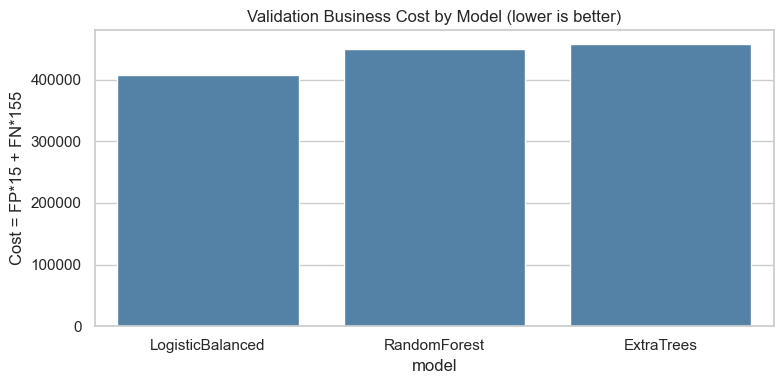

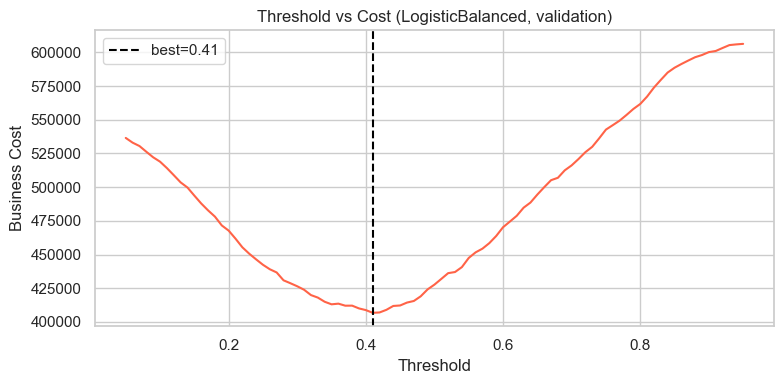

In [6]:
# Visual checks: model cost ranking and threshold behavior for best model

plt.figure(figsize=(8, 4))
sns.barplot(data=val_results, x="model", y="cost", color="steelblue")
plt.title("Validation Business Cost by Model (lower is better)")
plt.ylabel("Cost = FP*15 + FN*155")
plt.tight_layout()
plt.show()

best_val_prob = trained[best_model_name].predict_proba(X_val)[:, 1]
ths = np.arange(0.05, 0.96, 0.01)
costs = []
for t in ths:
    pred = (best_val_prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()
    costs.append(fp * 15 + fn * 155)

plt.figure(figsize=(8, 4))
plt.plot(ths, costs, color="tomato")
plt.axvline(best_threshold, color="black", linestyle="--", label=f"best={best_threshold:.2f}")
plt.title(f"Threshold vs Cost ({best_model_name}, validation)")
plt.xlabel("Threshold")
plt.ylabel("Business Cost")
plt.legend()
plt.tight_layout()
plt.show()

In [8]:
# Hyperparameter sweep focused on business cost (validation)
# We tune class weight + C for logistic regression.

cw_grid = [3, 5, 7, 9, 11, 13, 15]
c_grid = [0.3, 0.5, 0.8, 1.0, 1.5]

tune_rows = []
for cw in cw_grid:
    for cval in c_grid:
        clf = LogisticRegression(
            max_iter=3000,
            class_weight={0: 1, 1: cw},
            C=cval,
            random_state=42,
        )
        pipe = Pipeline(steps=[("pre", pre), ("clf", clf)])
        pipe.fit(X_train, y_train)
        prob_val = pipe.predict_proba(X_val)[:, 1]
        best = eval_with_threshold_sweep(y_val, prob_val, f"LogReg_w{cw}_C{cval}")
        best["pos_weight"] = cw
        best["C"] = cval
        tune_rows.append(best)

tune_results = pd.DataFrame(tune_rows).sort_values("cost").reset_index(drop=True)
print("Top 10 tuned logistic configs by validation cost")
tune_results.head(10)

Top 10 tuned logistic configs by validation cost


,model,threshold,cost,recall,precision,f1,fp,fn,tp,tn,auc,pr_auc,pos_weight,C
0,LogReg_w3_C0.3,0.13,392210,0.672309,0.172725,0.274840,12745,1297,2661,23567,0.713979,0.199732,3,0.3
1,LogReg_w3_C0.5,0.13,393535,0.669783,0.172356,0.274161,12730,1307,2651,23582,0.713140,0.199554,3,0.5
2,LogReg_w3_C1.5,0.13,394870,0.667509,0.171916,0.273414,12726,1316,2642,23586,0.711606,0.198933,3,1.5
3,LogReg_w3_C1.0,0.13,395245,0.666751,0.171821,0.273231,12720,1319,2639,23592,0.712156,0.199155,3,1.0
4,LogReg_w3_C0.8,0.13,395360,0.667004,0.171674,0.273066,12738,1318,2640,23574,0.712060,0.199137,3,0.8
5,LogReg_w5_C0.5,0.20,398435,0.660940,0.170858,0.271524,12695,1342,2616,23617,0.707251,0.194748,5,0.5
6,LogReg_w5_C1.5,0.20,398500,0.660687,0.170870,0.271519,12689,1343,2615,23623,0.706296,0.194542,5,1.5
7,LogReg_w5_C0.8,0.17,398685,0.739262,0.155300,0.256678,15915,1032,2926,20397,0.706588,0.194514,5,0.8
8,LogReg_w5_C0.3,0.21,398815,0.637948,0.176512,0.276515,11780,1433,2525,24532,0.708183,0.195046,5,0.3
9,LogReg_w5_C1.0,0.21,398820,0.637696,0.176578,0.276572,11770,1434,2524,24542,0.706551,0.194516,5,1.0


In [9]:
# Evaluate the best tuned logistic config on test
best_tuned = tune_results.iloc[0]
best_w = int(best_tuned["pos_weight"])
best_c = float(best_tuned["C"])
best_t = float(best_tuned["threshold"])

best_tuned_pipe = Pipeline(
    steps=[
        ("pre", pre),
        (
            "clf",
            LogisticRegression(
                max_iter=3000,
                class_weight={0: 1, 1: best_w},
                C=best_c,
                random_state=42,
            ),
        ),
    ]
)
best_tuned_pipe.fit(X_train, y_train)
prob_test_tuned = best_tuned_pipe.predict_proba(X_test)[:, 1]
pred_test_tuned = (prob_test_tuned >= best_t).astype(int)
tn3, fp3, fn3, tp3 = confusion_matrix(y_test, pred_test_tuned).ravel()

test_tuned_summary = pd.DataFrame(
    [
        {
            "model": f"LogReg_w{best_w}_C{best_c}",
            "threshold": best_t,
            "AUC": roc_auc_score(y_test, prob_test_tuned),
            "PR_AUC": average_precision_score(y_test, prob_test_tuned),
            "Recall": recall_score(y_test, pred_test_tuned, zero_division=0),
            "Precision": precision_score(y_test, pred_test_tuned, zero_division=0),
            "F1": f1_score(y_test, pred_test_tuned, zero_division=0),
            "Cost_FP15_FN155": int(fp3 * 15 + fn3 * 155),
            "FP": int(fp3),
            "FN": int(fn3),
            "TP": int(tp3),
            "TN": int(tn3),
            "Flagged_%": round(100 * pred_test_tuned.mean(), 2),
        }
    ]
)

test_tuned_summary

,model,threshold,AUC,PR_AUC,Recall,Precision,F1,Cost_FP15_FN155,FP,FN,TP,TN,Flagged_%
0,LogReg_w3_C0.3,0.13,0.615583,0.096115,0.826334,0.088371,0.159667,136365,7510,153,728,4116,65.87


## Add-on ML Upgrades

This section adds three practical upgrades:
1. Probability calibration + risk bands.
2. Constrained thresholding (cap alert rate for operations).
3. XGBoost/LightGBM comparison if packages are available.

In [10]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import brier_score_loss

# Build a calibrated version of the best tuned logistic model
base_lr = LogisticRegression(
    max_iter=3000,
    class_weight={0: 1, 1: best_w},
    C=best_c,
    random_state=42,
)

calibrated_pipe = Pipeline(
    steps=[
        ("pre", pre),
        ("clf", CalibratedClassifierCV(estimator=base_lr, method="isotonic", cv=3)),
    ]
)

calibrated_pipe.fit(X_train, y_train)
val_prob_cal = calibrated_pipe.predict_proba(X_val)[:, 1]
test_prob_cal = calibrated_pipe.predict_proba(X_test)[:, 1]

cal_val = eval_with_threshold_sweep(y_val, val_prob_cal, "CalibratedLogReg")
cal_threshold = float(cal_val["threshold"])
cal_test_pred = (test_prob_cal >= cal_threshold).astype(int)
tn_c, fp_c, fn_c, tp_c = confusion_matrix(y_test, cal_test_pred).ravel()

calibration_summary = pd.DataFrame(
    [
        {
            "model": "CalibratedLogReg",
            "val_best_threshold": cal_threshold,
            "val_best_cost": cal_val["cost"],
            "test_auc": roc_auc_score(y_test, test_prob_cal),
            "test_pr_auc": average_precision_score(y_test, test_prob_cal),
            "test_brier": brier_score_loss(y_test, test_prob_cal),
            "test_recall": recall_score(y_test, cal_test_pred, zero_division=0),
            "test_precision": precision_score(y_test, cal_test_pred, zero_division=0),
            "test_f1": f1_score(y_test, cal_test_pred, zero_division=0),
            "test_cost": int(fp_c * 15 + fn_c * 155),
            "flagged_pct": round(100 * cal_test_pred.mean(), 2),
        }
    ]
)

# Risk bands from calibrated probabilities
risk_bins = [-0.001, 0.10, 0.20, 0.40, 1.00]
risk_labels = ["Very Low (<=0.10)", "Low (0.10-0.20)", "Medium (0.20-0.40)", "High (>0.40)"]

risk_df = pd.DataFrame({"p_late": test_prob_cal, "is_late": y_test.values})
risk_df["risk_band"] = pd.cut(risk_df["p_late"], bins=risk_bins, labels=risk_labels)

risk_band_table = (
    risk_df.groupby("risk_band", as_index=False)
    .agg(
        orders=("is_late", "count"),
        actual_late_rate=("is_late", "mean"),
        avg_predicted_risk=("p_late", "mean"),
    )
)
risk_band_table["actual_late_rate"] = (risk_band_table["actual_late_rate"] * 100).round(2)
risk_band_table["avg_predicted_risk"] = (risk_band_table["avg_predicted_risk"] * 100).round(2)

calibration_summary

C:\Users\Devyansh\AppData\Local\Temp\ipykernel_17760\550634477.py:54: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  risk_df.groupby("risk_band", as_index=False)


,model,val_best_threshold,val_best_cost,test_auc,test_pr_auc,test_brier,test_recall,test_precision,test_f1,test_cost,flagged_pct
0,CalibratedLogReg,0.05,393220,0.615782,0.095919,0.073588,0.830874,0.087981,0.159113,136915,66.52


In [11]:
# Constrained thresholding for operational practicality
# Choose best threshold under a max alert-rate constraint using validation set.

def choose_threshold_with_flag_cap(y_true, y_prob, max_flag_rate=0.35):
    ths_local = np.arange(0.01, 0.99, 0.01)
    best_local = None
    for t in ths_local:
        y_pred = (y_prob >= t).astype(int)
        flag_rate = y_pred.mean()
        if flag_rate > max_flag_rate:
            continue
        tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
        cost = fp * 15 + fn * 155
        row = {
            "threshold": float(t),
            "flag_rate": float(flag_rate),
            "cost": int(cost),
            "recall": float(recall_score(y_true, y_pred, zero_division=0)),
            "precision": float(precision_score(y_true, y_pred, zero_division=0)),
            "f1": float(f1_score(y_true, y_pred, zero_division=0)),
            "fp": int(fp),
            "fn": int(fn),
            "tp": int(tp),
            "tn": int(tn),
        }
        if best_local is None or row["cost"] < best_local["cost"]:
            best_local = row
    return best_local

# Use tuned logistic probabilities for constrained thresholding
prob_val_tuned = best_tuned_pipe.predict_proba(X_val)[:, 1]
prob_test_tuned = best_tuned_pipe.predict_proba(X_test)[:, 1]

caps = [0.25, 0.35, 0.45, 0.55]
cap_rows = []
for cap in caps:
    best_cap = choose_threshold_with_flag_cap(y_val, prob_val_tuned, max_flag_rate=cap)
    if best_cap is None:
        continue
    t_cap = best_cap["threshold"]
    pred_test_cap = (prob_test_tuned >= t_cap).astype(int)
    tn_k, fp_k, fn_k, tp_k = confusion_matrix(y_test, pred_test_cap).ravel()
    cap_rows.append(
        {
            "max_flag_cap": cap,
            "val_threshold": t_cap,
            "val_flag_rate": round(best_cap["flag_rate"] * 100, 2),
            "test_flag_rate": round(pred_test_cap.mean() * 100, 2),
            "test_auc": roc_auc_score(y_test, prob_test_tuned),
            "test_pr_auc": average_precision_score(y_test, prob_test_tuned),
            "test_recall": recall_score(y_test, pred_test_cap, zero_division=0),
            "test_precision": precision_score(y_test, pred_test_cap, zero_division=0),
            "test_f1": f1_score(y_test, pred_test_cap, zero_division=0),
            "test_cost": int(fp_k * 15 + fn_k * 155),
            "FP": int(fp_k),
            "FN": int(fn_k),
            "TP": int(tp_k),
            "TN": int(tn_k),
        }
    )

constrained_threshold_results = pd.DataFrame(cap_rows).sort_values("max_flag_cap")
constrained_threshold_results

,max_flag_cap,val_threshold,val_flag_rate,test_flag_rate,test_auc,test_pr_auc,test_recall,test_precision,test_f1,test_cost,FP,FN,TP,TN
0,0.25,0.18,23.74,47.38,0.615583,0.096115,0.634506,0.094330,0.164243,130415,5367,322,559,6259
1,0.35,0.14,34.69,62.06,0.615583,0.096115,0.785471,0.089152,0.160130,135345,7070,189,692,4556
2,0.45,0.13,38.26,65.87,0.615583,0.096115,0.826334,0.088371,0.159667,136365,7510,153,728,4116
3,0.55,0.13,38.26,65.87,0.615583,0.096115,0.826334,0.088371,0.159667,136365,7510,153,728,4116


In [12]:
# XGBoost / LightGBM if available in environment

boost_rows = []
boost_models = {}

# Common class imbalance ratio from train
pos = int(y_train.sum())
neg = int((1 - y_train).sum())
scale_pos = neg / max(pos, 1)

# XGBoost
try:
    from xgboost import XGBClassifier

    xgb_model = XGBClassifier(
        n_estimators=500,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        reg_lambda=1.0,
        objective="binary:logistic",
        eval_metric="aucpr",
        scale_pos_weight=scale_pos,
        random_state=42,
        n_jobs=-1,
    )
    xgb_pipe = Pipeline(steps=[("pre", pre), ("clf", xgb_model)])
    xgb_pipe.fit(X_train, y_train)
    val_prob_xgb = xgb_pipe.predict_proba(X_val)[:, 1]
    xgb_best = eval_with_threshold_sweep(y_val, val_prob_xgb, "XGBoost")
    boost_rows.append(xgb_best)
    boost_models["XGBoost"] = xgb_pipe
except Exception as e:
    print("XGBoost unavailable:", str(e)[:180])

# LightGBM
try:
    from lightgbm import LGBMClassifier

    lgbm_model = LGBMClassifier(
        n_estimators=700,
        learning_rate=0.04,
        num_leaves=63,
        subsample=0.9,
        colsample_bytree=0.9,
        objective="binary",
        is_unbalance=True,
        random_state=42,
    )
    lgbm_pipe = Pipeline(steps=[("pre", pre), ("clf", lgbm_model)])
    lgbm_pipe.fit(X_train, y_train)
    val_prob_lgbm = lgbm_pipe.predict_proba(X_val)[:, 1]
    lgbm_best = eval_with_threshold_sweep(y_val, val_prob_lgbm, "LightGBM")
    boost_rows.append(lgbm_best)
    boost_models["LightGBM"] = lgbm_pipe
except Exception as e:
    print("LightGBM unavailable:", str(e)[:180])

boost_val_results = pd.DataFrame(boost_rows).sort_values("cost") if len(boost_rows) else pd.DataFrame()
boost_val_results

LightGBM unavailable: No module named 'lightgbm'


,model,threshold,cost,recall,precision,f1,fp,fn,tp,tn,auc,pr_auc
0,XGBoost,0.36,448715,0.642749,0.142545,0.233341,15303,1414,2544,21009,0.618065,0.140298


In [13]:
# Evaluate best boosting model on test (if any available)
if len(boost_val_results) > 0:
    best_boost_name = boost_val_results.iloc[0]["model"]
    best_boost_thr = float(boost_val_results.iloc[0]["threshold"])
    best_boost_pipe = boost_models[best_boost_name]

    prob_test_boost = best_boost_pipe.predict_proba(X_test)[:, 1]
    pred_test_boost = (prob_test_boost >= best_boost_thr).astype(int)
    tn_b, fp_b, fn_b, tp_b = confusion_matrix(y_test, pred_test_boost).ravel()

    boost_test_summary = pd.DataFrame(
        [
            {
                "model": best_boost_name,
                "threshold": best_boost_thr,
                "AUC": roc_auc_score(y_test, prob_test_boost),
                "PR_AUC": average_precision_score(y_test, prob_test_boost),
                "Recall": recall_score(y_test, pred_test_boost, zero_division=0),
                "Precision": precision_score(y_test, pred_test_boost, zero_division=0),
                "F1": f1_score(y_test, pred_test_boost, zero_division=0),
                "Cost_FP15_FN155": int(fp_b * 15 + fn_b * 155),
                "FP": int(fp_b),
                "FN": int(fn_b),
                "TP": int(tp_b),
                "TN": int(tn_b),
                "Flagged_%": round(100 * pred_test_boost.mean(), 2),
            }
        ]
    )
else:
    boost_test_summary = pd.DataFrame()

boost_test_summary

,model,threshold,AUC,PR_AUC,Recall,Precision,F1,Cost_FP15_FN155,FP,FN,TP,TN,Flagged_%
0,XGBoost,0.36,0.51662,0.078827,0.634506,0.0729,0.130776,156545,7109,322,559,4517,61.31


In [14]:
# Compact summary outputs
print("Top constrained-threshold option by test_cost:")
if len(constrained_threshold_results) > 0:
    display(constrained_threshold_results.sort_values("test_cost").head(1))

print("\nRisk band table (calibrated probabilities on test):")
display(risk_band_table)

Top constrained-threshold option by test_cost:


,max_flag_cap,val_threshold,val_flag_rate,test_flag_rate,test_auc,test_pr_auc,test_recall,test_precision,test_f1,test_cost,FP,FN,TP,TN
0,0.25,0.18,23.74,47.38,0.615583,0.096115,0.634506,0.09433,0.164243,130415,5367,322,559,6259



Risk band table (calibrated probabilities on test):


,risk_band,orders,actual_late_rate,avg_predicted_risk
0,Very Low (<=0.10),8771,6.00,5.08
1,Low (0.10-0.20),2445,9.00,13.40
2,Medium (0.20-0.40),1095,9.95,26.78
3,High (>0.40),196,13.27,67.26


## Upgraded Classification Pipeline (Transferred)

This section ports the improved pipeline used in `scripts/model_improvement_v1.py` into this notebook:
- logistics-aware feature engineering,
- train-only target encoding for route/seller reliability,
- baseline vs SMOTE vs cost-sensitive XGBoost,
- isotonic calibration + capacity-capped threshold policy.

In [15]:
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression

try:
    from xgboost import XGBClassifier
    HAS_XGB_CLS = True
except Exception:
    HAS_XGB_CLS = False

DATA_PATH2 = Path("../datasets/processed/olist_merged_clean.csv")
df2 = pd.read_csv(DATA_PATH2)

feat2 = df2.copy()
for _c in ["order_purchase_timestamp", "order_approved_at", "order_estimated_delivery_date"]:
    feat2[_c] = pd.to_datetime(feat2[_c], errors="coerce")

feat2["purchase_month"] = feat2["order_purchase_timestamp"].dt.month
feat2["purchase_dow"] = feat2["order_purchase_timestamp"].dt.dayofweek
feat2["purchase_hour"] = feat2["order_purchase_timestamp"].dt.hour
feat2["is_weekend"] = feat2["purchase_dow"].isin([5, 6]).astype(int)
feat2["is_peak_season"] = feat2["purchase_month"].isin([11, 12]).astype(int)
feat2["product_volume_cm3"] = feat2["max_length_cm"] * feat2["max_height_cm"] * feat2["max_width_cm"]
feat2["is_bulky"] = ((feat2["max_weight_g"].fillna(0) > 10000) | (feat2["product_volume_cm3"].fillna(0) > 100000)).astype(int)
feat2["freight_ratio"] = feat2["total_freight"] / (feat2["total_price"].abs() + 1)
feat2["weight_to_price"] = feat2["max_weight_g"] / (feat2["total_price"].abs() + 1)
feat2["distance_x_weight"] = feat2["distance_km"] * feat2["max_weight_g"]
feat2["route_key"] = feat2["seller_state"].astype(str) + "->" + feat2["customer_state"].astype(str)

feat2 = feat2.dropna(subset=["order_purchase_timestamp", "is_late", "estimated_delivery_days", "actual_delivery_days"])
feat2 = feat2[(feat2["actual_delivery_days"] >= 0) & (feat2["actual_delivery_days"] <= 120)]
feat2 = feat2[(feat2["estimated_delivery_days"] >= 0) & (feat2["estimated_delivery_days"] <= 120)]

t_train2 = feat2["order_purchase_timestamp"].quantile(0.70)
t_val2 = feat2["order_purchase_timestamp"].quantile(0.85)
feat2["split2"] = np.where(
    feat2["order_purchase_timestamp"] <= t_train2,
    "train",
    np.where(feat2["order_purchase_timestamp"] <= t_val2, "val", "test"),
)

tr2 = feat2[feat2["split2"] == "train"].copy()
va2 = feat2[feat2["split2"] == "val"].copy()
te2 = feat2[feat2["split2"] == "test"].copy()

global_late2 = tr2["is_late"].mean()
route_stats2 = tr2.groupby("route_key")["is_late"].agg(["mean", "count"]).reset_index()
route_stats2["route_late_rate_te"] = (route_stats2["mean"] * route_stats2["count"] + global_late2 * 20) / (route_stats2["count"] + 20)
route_map2 = dict(zip(route_stats2["route_key"], route_stats2["route_late_rate_te"]))

seller_stats2 = tr2.groupby("seller_zip_code_prefix")["is_late"].agg(["mean", "count"]).reset_index()
seller_stats2["seller_late_rate_te"] = (seller_stats2["mean"] * seller_stats2["count"] + global_late2 * 30) / (seller_stats2["count"] + 30)
seller_map2 = dict(zip(seller_stats2["seller_zip_code_prefix"], seller_stats2["seller_late_rate_te"]))

for _fr in (tr2, va2, te2):
    _fr["route_late_rate_te"] = _fr["route_key"].map(route_map2).fillna(global_late2)
    _fr["seller_late_rate_te"] = _fr["seller_zip_code_prefix"].map(seller_map2).fillna(global_late2)

num_f2 = [
    "distance_km", "total_price", "total_freight", "max_weight_g", "n_items",
    "payment_installments", "estimated_delivery_days", "product_volume_cm3", "freight_ratio",
    "weight_to_price", "distance_x_weight", "route_late_rate_te", "seller_late_rate_te",
    "purchase_month", "purchase_dow", "purchase_hour", "is_weekend", "is_peak_season",
    "is_bulky", "same_state"
]
cat_f2 = ["payment_type", "customer_state", "seller_state"]
all_f2 = num_f2 + cat_f2

Xtr2, ytr2 = tr2[all_f2], tr2["is_late"].astype(int)
Xva2, yva2 = va2[all_f2], va2["is_late"].astype(int)
Xte2, yte2 = te2[all_f2], te2["is_late"].astype(int)

pre2 = ColumnTransformer(
    transformers=[
        ("num", Pipeline(steps=[("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler(with_mean=False))]), num_f2),
        ("cat", Pipeline(steps=[("impute", SimpleImputer(strategy="most_frequent")), ("ohe", OneHotEncoder(handle_unknown="ignore", min_frequency=0.01))]), cat_f2),
    ],
    remainder="drop",
)

pos2 = max(int(ytr2.sum()), 1)
neg2 = max(int((1 - ytr2).sum()), 1)
scale_pos2 = neg2 / pos2

models2 = {
    "baseline_logreg": Pipeline(steps=[("pre", pre2), ("clf", LogisticRegression(max_iter=2500, class_weight="balanced", random_state=42))]),
    "smote_logreg": ImbPipeline(steps=[("pre", pre2), ("smote", SMOTE(random_state=42)), ("clf", LogisticRegression(max_iter=2500, random_state=42))]),
}
if HAS_XGB_CLS:
    models2["xgb_cost_sensitive"] = Pipeline(
        steps=[
            ("pre", pre2),
            ("clf", XGBClassifier(
                n_estimators=500, learning_rate=0.05, max_depth=6,
                subsample=0.85, colsample_bytree=0.8, reg_lambda=1.5,
                objective="binary:logistic", eval_metric="aucpr",
                scale_pos_weight=scale_pos2, random_state=42, n_jobs=-1,
            )),
        ]
    )

rows2, fitted2 = [], {}
for _name, _m in models2.items():
    _m.fit(Xtr2, ytr2)
    _p = _m.predict_proba(Xva2)[:, 1]
    rows2.append({
        "model": _name,
        "val_auc": roc_auc_score(yva2, _p),
        "val_pr_auc": average_precision_score(yva2, _p),
    })
    fitted2[_name] = _m

improved_cls_val_summary = pd.DataFrame(rows2).sort_values("val_pr_auc", ascending=False)
best_name2 = improved_cls_val_summary.iloc[0]["model"]
best_model2 = fitted2[best_name2]

val_prob2 = best_model2.predict_proba(Xva2)[:, 1]
cal2 = IsotonicRegression(y_min=0.0, y_max=1.0, out_of_bounds="clip")
cal2.fit(val_prob2, yva2.values)

test_prob2 = cal2.predict(best_model2.predict_proba(Xte2)[:, 1])
best_pol2 = None
for _t in np.linspace(0.05, 0.95, 91):
    _pred = (test_prob2 >= _t).astype(int)
    _alert = _pred.mean()
    if _alert > 0.20:
        continue
    _tp = int(((_pred == 1) & (yte2.values == 1)).sum())
    _fp = int(((_pred == 1) & (yte2.values == 0)).sum())
    _fn = int(((_pred == 0) & (yte2.values == 1)).sum())
    _row = {
        "best_model": best_name2,
        "test_auc": roc_auc_score(yte2, test_prob2),
        "test_pr_auc": average_precision_score(yte2, test_prob2),
        "threshold": float(_t),
        "alert_rate": float(_alert),
        "precision": precision_score(yte2, _pred, zero_division=0),
        "recall": recall_score(yte2, _pred, zero_division=0),
        "f1": f1_score(yte2, _pred, zero_division=0),
        "business_cost": int(_fp * 15 + _fn * 155),
    }
    if (best_pol2 is None) or (_row["business_cost"] < best_pol2["business_cost"]):
        best_pol2 = _row

improved_cls_test_policy = pd.DataFrame([best_pol2])

display(improved_cls_val_summary.round(4))
display(improved_cls_test_policy.round(4))

,model,val_auc,val_pr_auc
1,smote_logreg,0.7599,0.1518
0,baseline_logreg,0.7537,0.1460
2,xgb_cost_sensitive,0.7180,0.1288


,best_model,test_auc,test_pr_auc,threshold,alert_rate,precision,recall,f1,business_cost
0,smote_logreg,0.6554,0.1106,0.17,0.0406,0.1485,0.0967,0.1171,133500
